# Real-network geometry and hydrograph-shape pilot

**Question:** do the geometry and slope variables that helped the synthetic screen also explain our saved real-event responses?

This is a small exploratory analysis of **79 collapses in examples 03, 21, 55 and 56**: 63 independent unit collapses and 16 compound collapses. We selected up to 16 independent and four compound states per example by geometric diversity, without reading their responses. These four examples have relatively isolated floods in the preliminary hydrograph scan. This is a deliberate subset, not a representative sample of all rivers.

**Main result:** the existing resistance product remains useful for lag. The added geometry offers some information about peak excess, but the full synthetic predictor set does not consistently improve transfer between real networks. Temporal spread is too sensitive to event definition here to support a firm predictor claim.

No routing was rerun; existing results and legacy notebooks are preserved. Reproduce the tables with `RAPID/investigations/real_geometry_shape_pilot.py`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'network_variants').exists())
OUT=ROOT/'RAPID/assets/real_geometry_shape_pilot'
sys.path.insert(0,str(ROOT/'RAPID/investigations'))
from scan_event_shape import load
Y=['lag_shift_pct','temporal_spread_change_pct','peak_excess_change_pct']
labels=['Peak-lag change (%)','Temporal-spread change (%)','Peak-excess change (%)']
d=pd.read_csv(OUT/'analysis.csv',dtype={'example':str})
scores=pd.read_csv(OUT/'held_out_network_scores.csv',dtype={'example':str})
audit=pd.read_csv(OUT/'event_audit.csv',dtype={'example':str})
colors=dict(zip(['03','21','55','56'],plt.get_cmap('tab10').colors[:4]))
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
display(d.groupby(['example','kind']).size().unstack(fill_value=0).rename(columns={'indep':'Independent','compound_bubbles':'Compound'}))
display(d.groupby('example')[Y].agg(['min','median','max']).round(3))

kind,Compound,Independent
example,,
03,4,16
21,4,16
55,4,16
56,4,15


lag_shift_pct                ... peak_excess_change_pct              
                  min median    max  ...                    min median    max
example                              ...                                     
03             -4.440 -0.740  0.000  ...                 -0.684  0.315  1.451
21             -1.730 -0.595 -0.054  ...                  0.010  0.066  1.661
55             -3.495 -0.084  0.000  ...                 -0.068  0.025  0.579
56             -6.773 -1.223 -0.188  ...                 -0.452  0.299  3.988

[4 rows x 9 columns]

## Matched definitions and limits

- **Resistance:** $X=L_f E[-\log_{10}(\Lambda_K)]$, using the authoritative selected hydraulic domain. For non-closed units this is the enclosing compound, not the residual matched corridor. Every comparison has the original `S000_base` parent.
- **Paths:** enumerate all directed parent-domain paths, sum link lengths, and calculate each path's length-weighted harmonic width. $L_{eq}=\sum w_pL_p/\sum w_p$; elongation is $L_{eq}/\sum w_p$; dominance $D=\max w_p/\sum w_p$; $CV_L=\sigma(L_p)/\bar L_p$; $A_{LW}=L_{eq}/\bar L_p-1$. Negative association means longer paths tend to be narrower. Path weights describe geometry, not routed discharge allocation.
- **Slope:** parent boundary head drop from the saved monotone RAPID head profile, divided by the **shortest directed parent-domain path length**. This is an explicit real-network substitute for the synthetic centerline length, not an average of link slopes. Two candidates with nonpositive head drop were excluded.
- **Event:** begin when inlet forcing first changes; retain each outlet record through its own end, so slower parents retain their tails. Set a common discharge reference $Q_r=\max(Q_{in,start},Q_{in,end})$ and integrate $\max(Q-Q_r,0)$. This is thresholded event excess, **not a physical baseflow separation**. Repeat at $Q_r+0.05$ and $Q_r+0.10$ times the parent's peak excess.
- **Responses:** child/parent percentage changes in peak lag, temporal standard deviation of excess discharge, and peak excess. Lag is measured relative to the common input peak. Positive peak-excess change means a higher child peak; negative spread change means a narrower child event.

Additional island reruns are outside this pilot. Complex domains can have thousands of overlapping paths: their summed equivalent width and width dominance depend strongly on path multiplicity. These definitions match the synthetic analysis, but do not describe independent parallel channels in those cases.

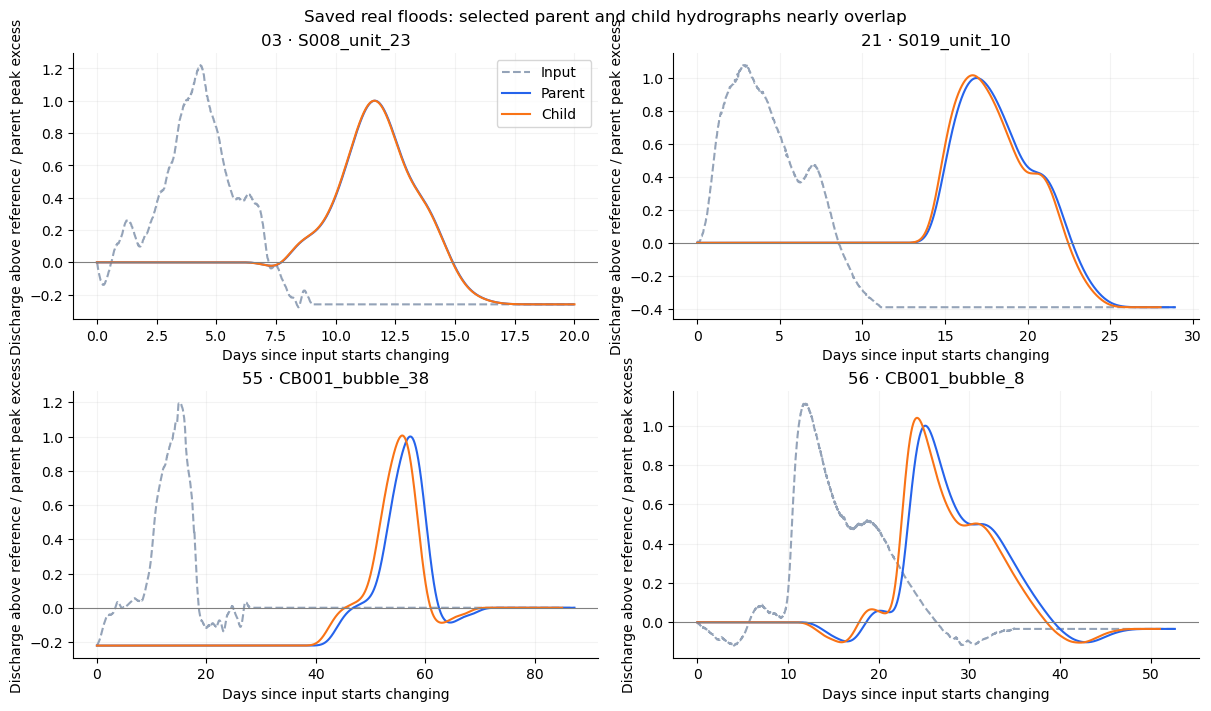

,parent_lag_hours,lag_sampling_step_pct,input_relative_error,parent_spinup_relative_error,parent_end_excess_fraction,child_end_excess_fraction
example,,,,,,
03,175.404167,0.211416,0.0,0.0,0.0,0.0
21,339.166667,0.054054,0.0,0.0,0.0,0.0
55,1015.972222,0.042105,0.0,0.0,0.0,0.0
56,318.900000,0.094073,0.0,0.0,0.0,0.0


In [2]:
fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
for ax,(example,g) in zip(axes.flat,d.groupby('example')):
    # Largest selected domain by geometry, not largest response.
    r=g.loc[g.length_fraction.idxmax()]
    bt,bq,bi=load(r.base_hydrograph);ct,cq,ci=load(r.hydrograph)
    first=np.flatnonzero(abs(bi-bi[0])>max(np.ptp(bi)*1e-6,1e-8))[0]
    origin=bt[first-1];ref=r.reference_discharge;scale=bq.max()-ref
    for t,q,label,color,style in [(bt,bi,'Input','#94a3b8','--'),(bt,bq,'Parent','#2563eb','-'),(ct,cq,'Child','#f97316','-')]:
        m=t>=origin
        ax.plot((t[m]-origin)/86400,(q[m]-ref)/scale,label=label,color=color,ls=style,lw=1.5)
    ax.axhline(0,color='gray',lw=.8);ax.set(title=f'{example} · {r.state_id}',xlabel='Days since input starts changing',ylabel='Discharge above reference / parent peak excess')
axes.flat[0].legend();fig.suptitle('Saved real floods: selected parent and child hydrographs nearly overlap')
fig.savefig(OUT/'event_context.png',dpi=160);display(fig);plt.close(fig)
audit['lag_sampling_step_pct']=100*audit[['parent_dt_seconds','child_dt_seconds']].max(axis=1)/(3600*audit.parent_lag_hours)
display(audit.groupby('example')[['parent_lag_hours','lag_sampling_step_pct','input_relative_error','parent_spinup_relative_error','parent_end_excess_fraction','child_end_excess_fraction']].max().round(6))

Identical inlet forcing, parent spin-up and complete excess tails passed the checks. Doubling the output sampling interval changed spread responses by at most 0.0019 percentage points and peak-excess responses by at most 0.0077 percentage points; this is a saved-output sampling check, not a rerouting convergence test. Peak times are sampled, not interpolated: changes below roughly **0.04–0.21 percentage points of parent lag**, depending on example, should not be overinterpreted.

Median absolute changes are **0.486% in lag, 0.033% in temporal spread, and 0.113% in peak excess**. These are much smaller than many synthetic responses. Some collapses broaden or lower the peak rather than sharpening it.

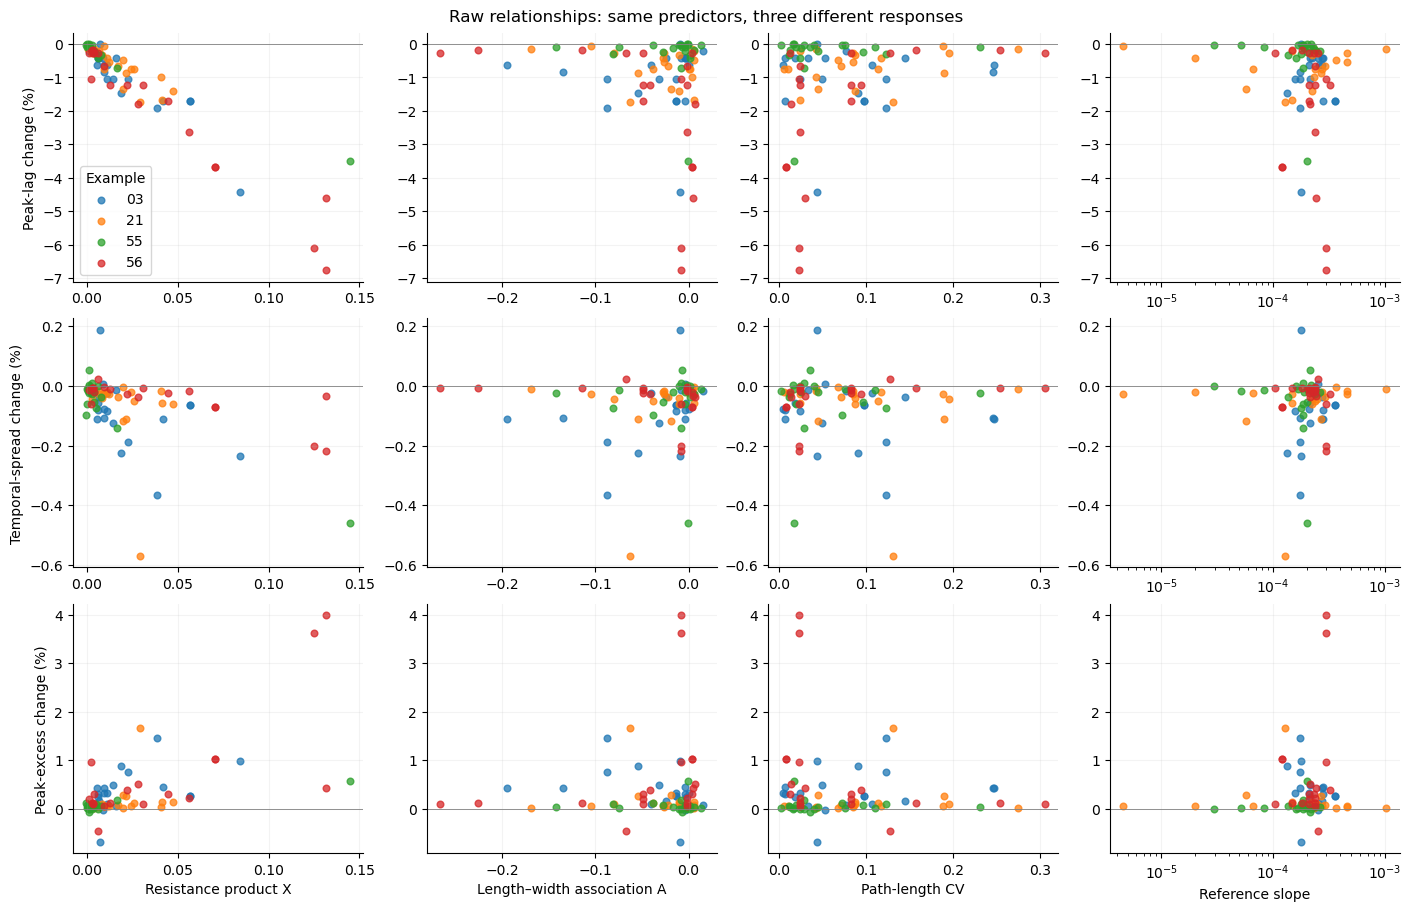

In [3]:
features=['resistance_predictor','signed_length_width_association','parent_path_length_cv','domain_reference_slope']
flabels=['Resistance product X','Length–width association A','Path-length CV','Reference slope']
fig,axes=plt.subplots(3,4,figsize=(14,9),constrained_layout=True)
for i,y in enumerate(Y):
    for j,x in enumerate(features):
        ax=axes[i,j]
        for example,g in d.groupby('example'):
            ax.scatter(g[x],g[y],s=23,color=colors[example],alpha=.75,label=example)
        ax.axhline(0,color='gray',lw=.6)
        if j==3:ax.set_xscale('log')
        if j==0:ax.set_ylabel(labels[i])
        if i==2:ax.set_xlabel(flabels[j])
axes[0,0].legend(title='Example');fig.suptitle('Raw relationships: same predictors, three different responses')
fig.savefig(OUT/'predictor_relationships.png',dpi=160);display(fig);plt.close(fig)

## Predicting a network that was left out

Fit on three networks and predict the fourth; repeat for all four. All states from the held-out network stay together. Models use standardized raw features and **Ridge with fixed alpha 10**, without tuning. The scores below pool all held-out predictions; they are not averages of per-network $R^2$. Negative $R^2$ means squared error exceeds the pooled observed-mean benchmark. Per-network scores, MAE and a training-mean baseline are saved in the CSVs.

This small real pilot uses a regularized linear model; the larger synthetic screen used nonlinear boosted trees. Differences between their scores cannot be attributed only to the geometry.

The compact set is $[X,L_{eq},elongation,D]$. Arrangement adds $CV_L,A_{LW}$; the full set also adds slope. Five simple product axes were declared before fitting; selecting the best-looking one here remains exploratory.

response,lag_shift_pct,temporal_spread_change_pct,peak_excess_change_pct
model,,,
resistance_product,0.741,-0.005,0.196
compact,0.764,-0.595,0.362
compact_plus_arrangement,0.761,-0.673,0.365
compact_plus_slope,0.758,-0.541,0.342
compact_plus_all,0.754,-0.622,0.334
product_X_CV,0.061,0.200,0.040
product_X_A,-0.120,0.159,0.076
product_Lf_elongation_D,0.527,-1.469,0.581


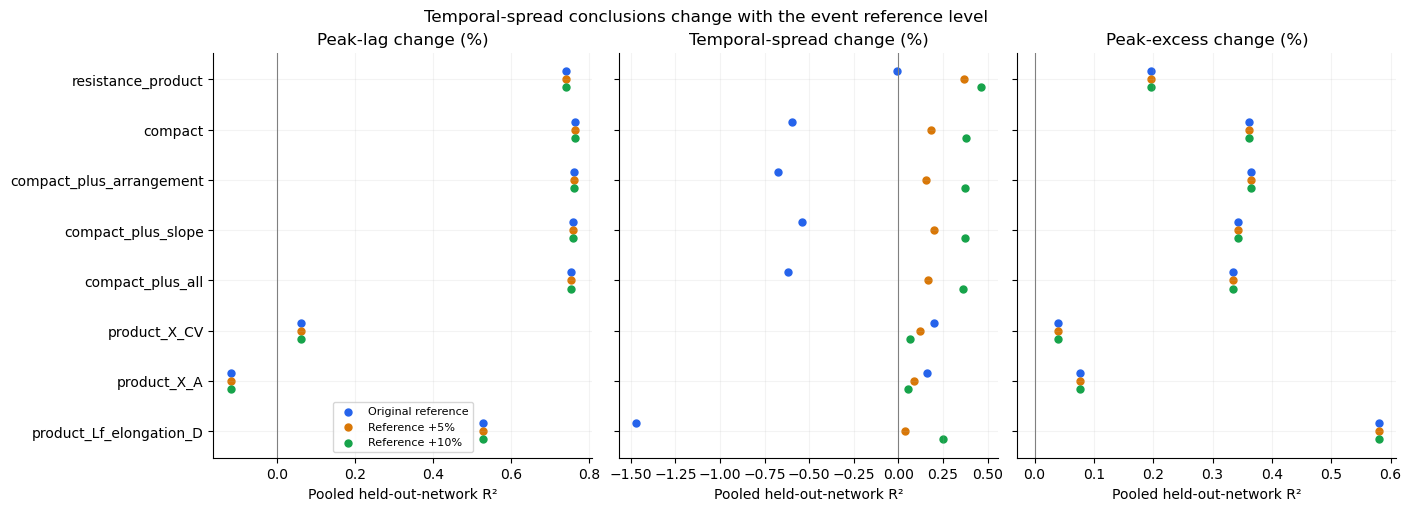

response,lag_shift_pct,temporal_spread_change_pct,peak_excess_change_pct
model,,,
compact,0.793,-0.727,0.439
compact_plus_all,0.784,-0.775,0.397
compact_plus_arrangement,0.795,-0.767,0.433
compact_plus_slope,0.782,-0.728,0.416
product_Lf_elongation_D,0.545,-2.123,0.471
product_X_A,-0.183,0.175,0.072
product_X_CV,0.000,0.122,0.069
resistance_product,0.812,-0.473,0.384


In [4]:
models=['resistance_product','compact','compact_plus_arrangement','compact_plus_slope','compact_plus_all','product_X_CV','product_X_A','product_Lf_elongation_D']
pooled=scores[scores.example=='pooled']
display(pooled.pivot(index='model',columns='response',values='r2').reindex(models)[Y].round(3))
fig,axes=plt.subplots(1,3,figsize=(14,5),constrained_layout=True)
for ax,y,label in zip(axes,Y,labels):
    for k,(prefix,offset,color) in enumerate([('',-.16,'#2563eb'),('threshold_0.05_',0,'#d97706'),('threshold_0.10_',.16,'#16a34a')]):
        s=pd.read_csv(OUT/(prefix+'held_out_network_scores.csv'),dtype={'example':str})
        vals=s[(s.example=='pooled')&(s.response==y)].set_index('model').r2.reindex(models)
        ax.scatter(vals,np.arange(len(models))+offset,c=color,s=25,label=['Original reference','Reference +5%','Reference +10%'][k])
    ax.axvline(0,color='gray',lw=.8);ax.set(title=label,xlabel='Pooled held-out-network R²',yticks=np.arange(len(models)),yticklabels=models if ax==axes[0] else [])
    ax.invert_yaxis()
axes[0].legend(fontsize=8);fig.suptitle('Temporal-spread conclusions change with the event reference level')
fig.savefig(OUT/'validation_and_thresholds.png',dpi=160);display(fig);plt.close(fig)
ind=pd.read_csv(OUT/'independent_held_out_network_scores.csv',dtype={'example':str})
display(ind[(ind.example=='pooled')&ind.model.isin(models)].pivot(index='model',columns='response',values='r2')[Y].round(3))

**What survives these checks?**

1. **Lag:** $X$ alone gives pooled held-out $R^2=0.741$; compact geometry gives 0.764 and all additions 0.754. On independent states alone, $X$ gives 0.811 versus 0.780 for the full set. The resistance relationship transfers more clearly than the incremental benefit of the extra variables.
2. **Peak excess:** compact geometry raises $R^2$ from 0.196 to 0.362; the full set gives 0.334. The simple product $L_f\times elongation\times D$ is promising at 0.581 (0.47 on independent states alone). It deserves a separate validation sample, not a final universal formula.
3. **Temporal spread:** adding all variables reduces $R^2$ from −0.005 to −0.622 at the original threshold. $X\times CV_L$ gives 0.200, but falls to about 0.060 at the higher threshold. Meanwhile $X$ rises to 0.457. **The predictor ranking is not stable to event definition.**
4. **Slope:** no consistent added benefit in this subset, unlike the synthetic screen. These four real events do not independently vary slope, geometry and forcing; this is not evidence that slope is physically irrelevant.

For peak excess, raising the reference simply rescales each pair's denominator; its near-perfect rank stability is largely algebraic, not independent validation of the event definition.

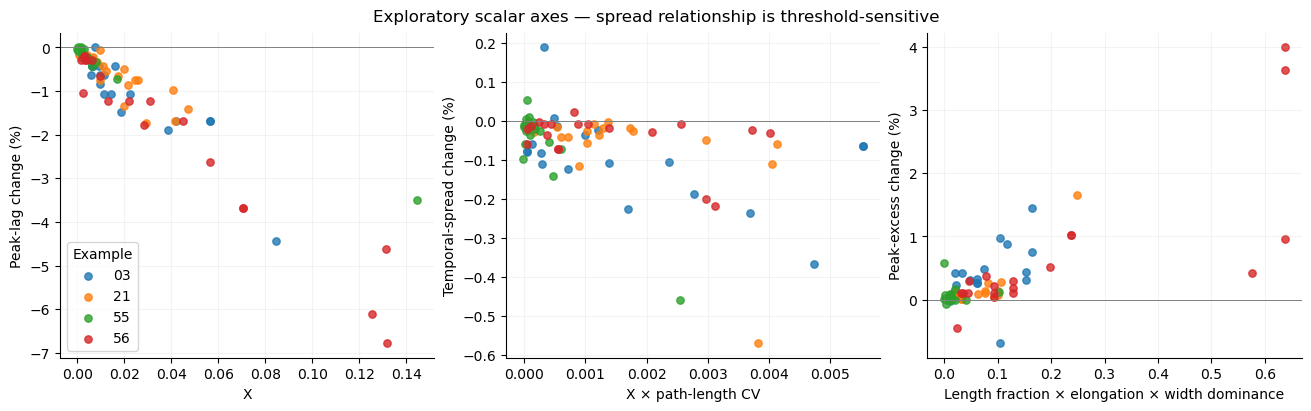

In [5]:
axes_x=['resistance_predictor','product_X_CV','product_Lf_elongation_D']
xlabels=['X','X × path-length CV','Length fraction × elongation × width dominance']
d['product_X_CV']=d.resistance_predictor*d.parent_path_length_cv
d['product_Lf_elongation_D']=d.length_fraction*d.parent_elongation*d.parent_dominant_width_fraction
fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
for ax,x,y,xlabel,ylabel in zip(axes,axes_x,Y,xlabels,labels):
    for example,g in d.groupby('example'):
        ax.scatter(g[x],g[y],c=[colors[example]],s=28,label=example,alpha=.8)
    ax.axhline(0,color='gray',lw=.7);ax.set(xlabel=xlabel,ylabel=ylabel)
axes[0].legend(title='Example');fig.suptitle('Exploratory scalar axes — spread relationship is threshold-sensitive')
fig.savefig(OUT/'simple_product_axes.png',dpi=160);display(fig);plt.close(fig)

## Why direct synthetic-model transfer fails

The frozen synthetic models are also applied without fitting to any real response. They fail, especially for event shape. This is a useful mismatch diagnosis rather than a predictor competition: the real forcing differs, the event-reference definition differs, and much of the geometry lies outside the synthetic training range.

**Every real collapse here has a smaller length fraction than the synthetic grid:** real 0.0018–0.1885 versus synthetic 0.2353–0.7222. Around 41% also have a smaller equivalent length. Some real domains have up to 2,636 overlapping paths, far beyond the simple synthetic geometries; path dominance becomes very small. A tree model cannot extrapolate smoothly beyond its training range.

These checks support extending the synthetic design toward **small affected domains within long networks**. They do not establish that length fraction alone causes the synthetic–real discrepancy.

In [6]:
display(pd.read_csv(OUT/'feature_ranges.csv').round(5))
display(pd.read_csv(OUT/'synthetic_transfer_scores.csv').round(3))
t=pd.read_csv(OUT/'threshold_sensitivity.csv',dtype={'example':str})
rows=[]
for y in Y[1:]:
    w=t.pivot(index=['example','kind','state_id'],columns='reference_increment',values=y)
    rows.append({'Response':y,'Original vs +10% correlation':w[0.].corr(w[.1]),
                 'Median absolute difference (percentage points)':(w[.1]-w[0.]).abs().median(),
                 'Maximum absolute difference (percentage points)':(w[.1]-w[0.]).abs().max()})
display(pd.DataFrame(rows).round(4))

,feature,synthetic_min,synthetic_max,real_min,real_max,outside_fraction
0,resistance_log,0.04907,1.18909,-0.00824,1.59235,0.11392
1,length_fraction,0.23529,0.72222,0.00179,0.18846,1.00000
2,width_fraction,0.50000,1.00000,0.18200,1.00000,0.11392
3,parent_equivalent_length,2000.00000,29000.00000,501.25540,16426.63335,0.40506
4,parent_elongation,2.22222,116.00000,0.03590,8.79094,0.25316
5,parent_dominant_width_fraction,0.40911,0.90000,0.00054,0.94362,0.35443
6,parent_path_length_cv,0.00000,0.20000,0.00308,0.30543,0.07595
7,signed_length_width_association,-0.12000,0.16000,-0.26659,0.01584,0.07595
8,domain_reference_slope,0.00005,0.00050,0.00000,0.00103,0.05063


,model,response,r2,mae,observed_abs_median,predicted_abs_median
0,resistance_product,lag_shift_pct,-1.003,1.344,0.486,0.516
1,resistance_product,temporal_spread_change_pct,-30644.782,17.734,0.033,18.375
2,resistance_product,peak_excess_change_pct,-258.934,10.703,0.113,10.962
3,compact_plus_all,lag_shift_pct,-7.017,3.464,0.486,4.085
4,compact_plus_all,temporal_spread_change_pct,-3105.604,5.243,0.033,4.993
5,compact_plus_all,peak_excess_change_pct,-38.462,3.476,0.113,3.231


,Response,Original vs +10% correlation,Median absolute difference (percentage points),Maximum absolute difference (percentage points)
0,temporal_spread_change_pct,0.7878,0.0114,0.4181
1,peak_excess_change_pct,1.0000,0.0125,0.4431


## Implications for the next investigation

Keep resistance × length fraction × exposure as the main lag predictor. Carry the elongation/dominance product forward as a **candidate for peak-excess change**, with no claim yet that it works across all rivers. Settle a reproducible flood-event/background definition before selecting a temporal-spread predictor: here reference sensitivity is comparable to the effect being predicted.

The next useful synthetic extension is smaller local collapses embedded in longer networks, followed by a separate set of real networks and the missing island reruns. We should also check whether path-multiplicity effects require a more local branch definition for complex real compounds. Four networks and 79 dependent comparisons cannot establish a universal geometry-only law.

All selection details, exclusions, predictor values, reference-level sensitivity, per-network scores and transfer diagnostics are in `RAPID/assets/real_geometry_shape_pilot/`.